## Практическое задание №3

В файле **WIPO-GII_2022.xlsx** содержаться данные по странам о показателях, используемых для расчета Global Innovation Index за 2022 год. 

### В файле следующие переменные:																																
- Country
- Business environment
- Business sophistication index
- Citable documents H-index
- Creative goods and services
- Creative goods exports, % total trade
- Creative outputs index
- Cultural and creative services exports, % total trade
- Domestic market scale, bn PPP
- Ecological sustainability
- Expenditure on education, % GDP
- Firms offering formal training, %
- General infrastructure
- Government effectiveness
- Government's online service
- Graduates in science and engineering, %
- Gross expenditure on R&D, % GDP
- High-tech exports, % total trade
- High-tech imports, % total trade
- High-tech manufacturing, %
- Human capital and research index
- Information and Communications Technology access
- Information and Communications Technology services exports, % total trade
- Information and Communications Technology services imports, % total trade
- Information and Communications Technology use
- Infrastructure index
- Intangible assets
- Joint venture/strategic alliance deals/bn PPP GDP
- Knowledge absorption
- Knowledge and technology outputs index
- Knowledge workers
- Knowledge-intensive employment, %
- Logistics performance
- Market sophistication index
- Mobile app creation/bn PPP GDP
- Online creativity
- PISA scales in reading, maths and science
- Political and operational stability
- Political environment
- Pupil-teacher ratio, secondary
- QS university ranking average score of top 3 universities
- Research and development (R&D)
- Scientific and technical articles/bn PPP GDP
- Software spending, % GDP
- Tertiary education
- Tertiary enrolment, % gross
- University-industry R&D collaboration
- Region
- Region2
- Euro area
- European Union
- OECD members
- Least developed countries
- Income
- High income

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import calinski_harabasz_score, silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

df1 = pd.read_excel('WIPO-GII_2022.xlsx')

Выполните, пожалуйста, задания.

**1. Построение признакового пространства и снижение размерности для кластеризации**

- Выберите не менее 10 числовых признаков из датасета, которые потенциально подходят для построения модели кластеризации. Обоснуйте их выбор (информативность, вариативность, отсутствие пропусков, предметный смысл).

- Проведите корреляционный анализ выбранных признаков. Сделайте вывод о наличии или отсутствии мультиколлинеарности.

- При наличии значимых корреляций выполните снижение размерности данных. Используйте метод главных компонент (PCA). Возможно, что имеет смысл выделить компоненты не на основе всех рассматриваемых признаков, а только на части изначально отобранных. Определите оптимальное количество компонент. Для каждой выделенной компоненты укажите процент объяснённой вариации; проанализируйте нагрузки; дайте компоненте осмысленное название и обоснуйте его.

- Сохраните полученные компоненты в датасете в виде новых переменных и используйте их для дальнейшей кластеризации.

- Сформируйте финальный список признаков по которым будет проведена кластеризация. Это могут быть только исходные признаки; только сформированные компоненты или же комбинация из исходных признаков и компонентов. Приведите аргументы в пользу того, что финальный список признаков может быть использован для кластеризации объектов наблюдения.

**!Если не удается выделить компоненты на имеющихся данных, то приведите расчеты и аргументы, подтверждающие это.**

In [3]:
numeric_features = df1.select_dtypes(include='number').filter(regex='_2022$').columns.tolist()
display(pd.Series(numeric_features, name='Количественные показатели').to_frame())

,Количественные показатели
0,Business environment_2022
1,Business sophistication index_2022
2,Citable documents H-index_2022
3,Creative goods and services_2022
4,"Creative goods exports, % total trade_2022"
5,Creative outputs index_2022
6,"Cultural and creative services exports, % tota..."
7,"Domestic market scale, bn PPP$_2022"
8,Ecological sustainability_2022
9,"Expenditure on education, % GDP_2022"


**Выбор 10 числовых признаков**

Для кластеризации выбраны показатели, характеризующие условия для инноваций, подготовку кадров, научную деятельность и использование технологий. Для анализа я рассматриваю только показатели за 2022 год.

| Признак | Что показывает |
| --- | --- |
| Government effectiveness | Характеризует эффективность государственного управления и институциональные условия для развития науки и бизнеса. |
| General infrastructure | Отражает инфраструктурные условия, необходимые для деятельности предприятий и внедрения технологий. |
| Information and Communications Technology access | Показывает доступность инфраструктуры, важной для распространения знаний и технологий. |
| Expenditure on education, % GDP | Характеризует финансирование образования. |
| Graduates in science and engineering, % | Отражает долю выпускников по научным и инженерным направлениям. |
| Gross expenditure on R&D, % GDP | Характеризует вложения в исследования и разработки. |
| Scientific and technical articles/bn PPP$ GDP | Отражает результативность научной деятельности с учётом масштаба экономики. |
| Knowledge-intensive employment, % | характеризует долю занятых в профессиях, требующих высокой квалификации и знаний. |
| High-tech manufacturing, % | Показывает роль высокотехнологичного производства в экономике. |
| High-tech exports, % total trade | Характеризует участие страны в международной торговле высокотехнологичными продуктами. |


На следующем шаге проверим корреляции между выбранными признаками, чтобы выяснить, насколько они дублируют информацию друг друга и нужно ли снижать размерность данных.

In [4]:
features = [
    'Government effectiveness_2022',
    'General infrastructure_2022',
    'Information and Communications Technology access_2022',
    'Expenditure on education, % GDP_2022',
    'Graduates in science and engineering, %_2022',
    'Gross expenditure on R&D, % GDP_2022',
    'Scientific and technical articles/bn PPP$ GDP_2022',
    'Knowledge-intensive employment, %_2022',
    'High-tech manufacturing, %_2022',
    'High-tech exports, % total trade_2022',
]

X = df1[features].dropna()


feature_stats = pd.DataFrame({
    'count': X.count(),
    'nunique': X.nunique(),
    'min': X.min(),
    'max': X.max(),
    'std': X.std()
})
feature_stats['missing_before'] = df1[features].isna().sum()
display(feature_stats.round(2))
print(f'Рабочая выборка: {X.shape[0]} стран, {X.shape[1]} признаков.')
print(f'Исключено стран с пропусками: {len(df1) - len(X)} из {len(df1)}.')

,count,nunique,min,max,std,missing_before
Government effectiveness_2022,132,124,0.0,100.0,19.79,7
General infrastructure_2022,132,113,2.9,76.2,15.48,7
Information and Communications Technology access_2022,132,109,0.0,99.6,17.47,7
"Expenditure on education, % GDP_2022",132,114,0.0,100.0,18.98,7
"Graduates in science and engineering, %_2022",132,98,0.0,100.0,28.09,7
"Gross expenditure on R&D, % GDP_2022",132,99,0.0,100.0,19.49,7
Scientific and technical articles/bn PPP$ GDP_2022,132,121,0.0,100.0,23.70,7
"Knowledge-intensive employment, %_2022",132,117,0.0,100.0,25.83,7
"High-tech manufacturing, %_2022",132,102,0.0,100.0,25.19,7
"High-tech exports, % total trade_2022",132,115,0.0,100.0,25.98,7


Рабочая выборка: 132 стран, 10 признаков.
Исключено стран с пропусками: 7 из 139.


**Вывод по отбору признаков.**<br>
В исходном файле 139 стран. Для 7 стран отсутствуют все 46 количественных показателей за 2022 год, поэтому эти строки исключены. В результате для каждого из 10 выбранных признаков имеется 132 страны без пропусков, чего достаточно для анализа.

Выбранные признаки различаются между странами, то есть число уникальных значений составляет от 98 до 124, стандартное отклонение от 15,48 до 28,09. Таким образом, среди них нет постоянных показателей, которые не позволяют различать страны.
Выбранные признаки охватывают несколько содержательных сторон технического развития.

**Корреляционный анализ**<br>

Для начала рассчитаем коэффициенты корреляции Пирсона и построим тепловую карту. Для удобства на графиках и в таблицах используем сокращённые русские названия.

Условно будем считать сильными связи с $|r|>= 0,7$. Статистическую значимость корреляций проверим с помощью Пирсона, сравним исходные p-значения с 0,05. 
Если p-значение меньше 0,05, будем считать линейную связь статистически значимой. 

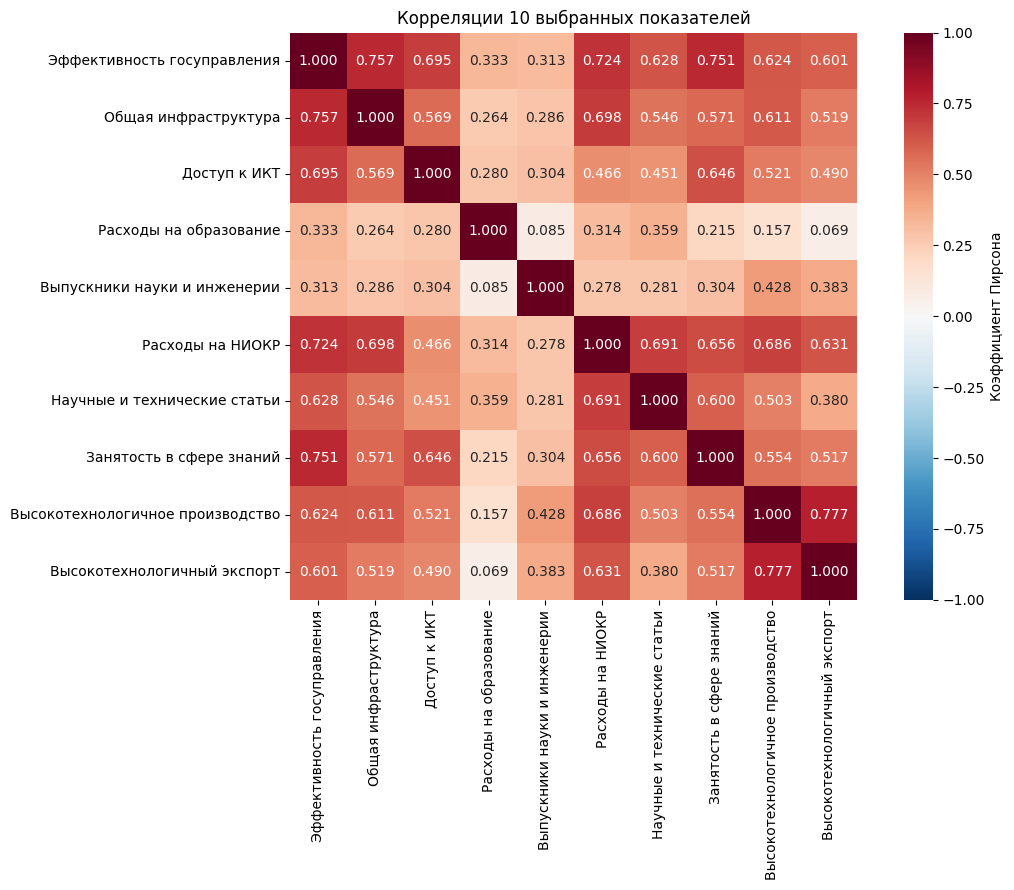

,Признак 1,Признак 2,r,p_value,Значима (p < 0.05)
0,Высокотехнологичное производство,Высокотехнологичный экспорт,0.776834,6.910342e-28,True
1,Эффективность госуправления,Общая инфраструктура,0.757320,8.035093e-26,True
2,Эффективность госуправления,Занятость в сфере знаний,0.750890,3.493769e-25,True
3,Эффективность госуправления,Расходы на НИОКР,0.724153,1.005068e-22,True


Сильных связей: 4 из 45 пар.


In [5]:
from scipy.stats import pearsonr

feature_names = dict(zip(features, [
    'Эффективность госуправления',
    'Общая инфраструктура',
    'Доступ к ИКТ',
    'Расходы на образование',
    'Выпускники науки и инженерии',
    'Расходы на НИОКР',
    'Научные и технические статьи',
    'Занятость в сфере знаний',
    'Высокотехнологичное производство',
    'Высокотехнологичный экспорт',
]))

corr_matrix = X.corr(method='pearson')
#display(corr_matrix.rename(index=feature_names, columns=feature_names).round(3))

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix.rename(index=feature_names, columns=feature_names),
    annot=True, fmt='.3f', cmap='RdBu_r', vmin=-1, vmax=1,
    square=True, cbar_kws={'label': 'Коэффициент Пирсона'},
)

plt.title('Корреляции 10 выбранных показателей')
plt.tight_layout()
plt.show()

pairs = []
for i, first in enumerate(features):
    for second in features[i + 1:]:
        r, p_value = pearsonr(X[first], X[second])
        pairs.append({
            'Признак 1': feature_names[first],
            'Признак 2': feature_names[second],
            'r': r,
            'p_value': p_value,
        })

correlation_pairs = pd.DataFrame(pairs)
correlation_pairs['Значима (p < 0.05)'] = correlation_pairs['p_value'] < 0.05

strong_pairs = correlation_pairs.loc[
    correlation_pairs['r'].abs() >= 0.7
].sort_values('r', ascending=False)

display(strong_pairs.reset_index(drop=True))
print(f'Сильных связей: {len(strong_pairs)} из {len(correlation_pairs)} пар.')

**Вывод по корреляциям.**<br>
Найдены 4 сильные положительные связи:

- высокотехнологичное производство и высокотехнологичный экспорт: r = 0,78;
- эффективность госуправления и общая инфраструктура: r = 0,76;
- эффективность госуправления и занятость в сфере знаний: r = 0,75;
- эффективность госуправления и расходы на НИОКР: r = 0,72.

Все четыре сильные связи статистически значимы, так как исходные p-значения теста Пирсона меньше 0,05.Сильные корреляции указывают на наличие мультиколлинеарности, то есть часть выбранных признаков передаёт похожую информацию. Поэтому применим PCA ко всем 10 признакам. Так мы сможем сократить размерность данных, не исключая отдельные показатели вручную.

**Стандартизация и выбор числа главных компонент**

Перед PCA проведём z-стандартизацию: вычтем среднее и разделим на стандартное отклонение. Хотя все показатели находятся в пределах 0–100, их разброс различается, поэтому без стандартизации признаки с большей дисперсией получили бы больший вес.

,Собственное значение,"Объяснённая вариация, %","Накопленная вариация, %"
0,5.535,55.345,55.345
1,1.121,11.209,66.554
2,0.801,8.011,74.565
3,0.662,6.616,81.180
4,0.579,5.794,86.974
5,0.433,4.333,91.307
6,0.311,3.112,94.419
7,0.218,2.176,96.595
8,0.187,1.866,98.461
9,0.154,1.539,100.000


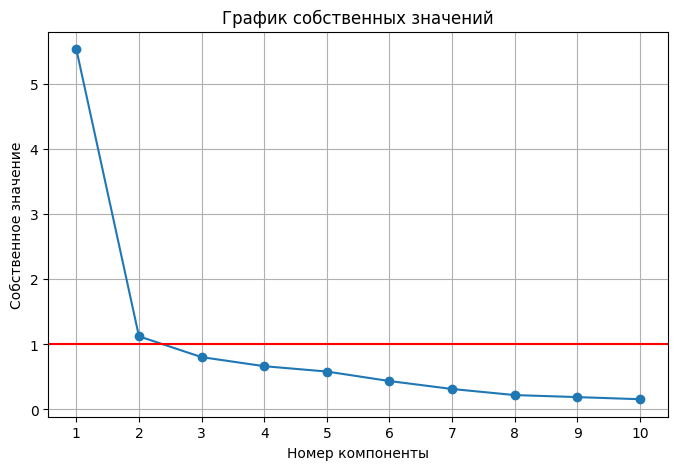

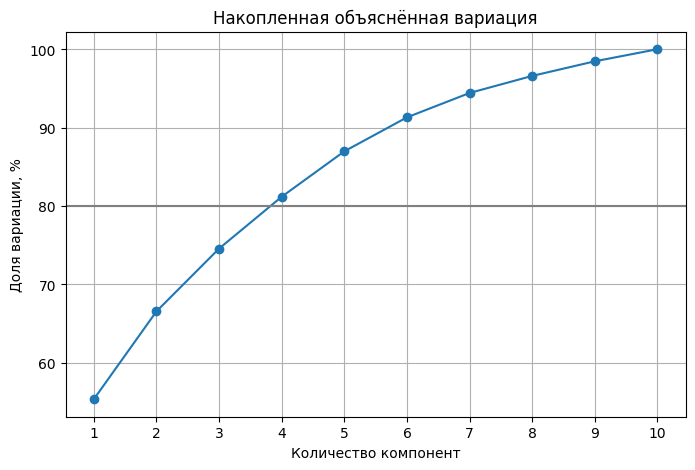

Компонент по критерию Кайзера: 2
Они объясняют, %: 66.55
Компонент для сохранения 80%: 4


In [7]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    index=X.index,
    columns=features
)

pca_full = PCA()
pca_full.fit(X_scaled)

eigenvalues = pca_full.explained_variance_ * (len(X) - 1) / len(X)
variance_share = pca_full.explained_variance_ratio_
cumulative_share = variance_share.cumsum()

pca_diagnostics = pd.DataFrame({
    'Собственное значение': eigenvalues,
    'Объяснённая вариация, %': variance_share * 100,
    'Накопленная вариация, %': cumulative_share * 100
})
display(pca_diagnostics.round(3))

component_numbers = range(1, len(eigenvalues) + 1)

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, eigenvalues, 'o-')
plt.axhline(1, color='red')
plt.title('График собственных значений')
plt.xlabel('Номер компоненты')
plt.ylabel('Собственное значение')
plt.xticks(component_numbers)
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, cumulative_share * 100, 'o-')
plt.axhline(80, color='gray')
plt.title('Накопленная объяснённая вариация')
plt.xlabel('Количество компонент')
plt.ylabel('Доля вариации, %')
plt.xticks(component_numbers)
plt.grid()
plt.show()

n_components = (eigenvalues > 1).sum()

n_components_80 = (cumulative_share < 0.8).sum() + 1

print('Компонент по критерию Кайзера:', n_components)
print('Они объясняют, %:', round(variance_share[:n_components].sum() * 100, 2))
print('Компонент для сохранения 80%:', n_components_80)

**Выбор числа компонент.**<br>
Собственные значения первых двух компонент равны 5,535 и 1,121, у третьей = 0,801, чем дальше, тем меньше. Для сохранения не менее 80% вариации понадобились бы четыре компоненты, которые вместе объясняют 81,18%. Мы оставляем две компоненты по критерию Кайзера (который, как я понял, прямо на семинаре не вводили, но обсуждали), чтобы получить более компактное и понятное описание стран. При этом учитываем, что 33,45% вариации теряется. На графике особенно заметно важность первой компоненты.

Первая компонента объясняет 55,35%, вторая 11,21%, то есть в сумме 66,55% вариации. Выбираем это решение как компактное представление общей структуры данных, размерность сокращается с 10 до 2, обе компоненты объясняют больше вариации, чем один стандартизированный исходный признак.

В то же время да, мы теряем 33,45% вариации. Такое решение подходит для укрупнённой сегментации, но может скрывать различия стран по отдельным показателям. (Опять же мы решили взять именно 2 компоненты именно из критерия Кайзера)

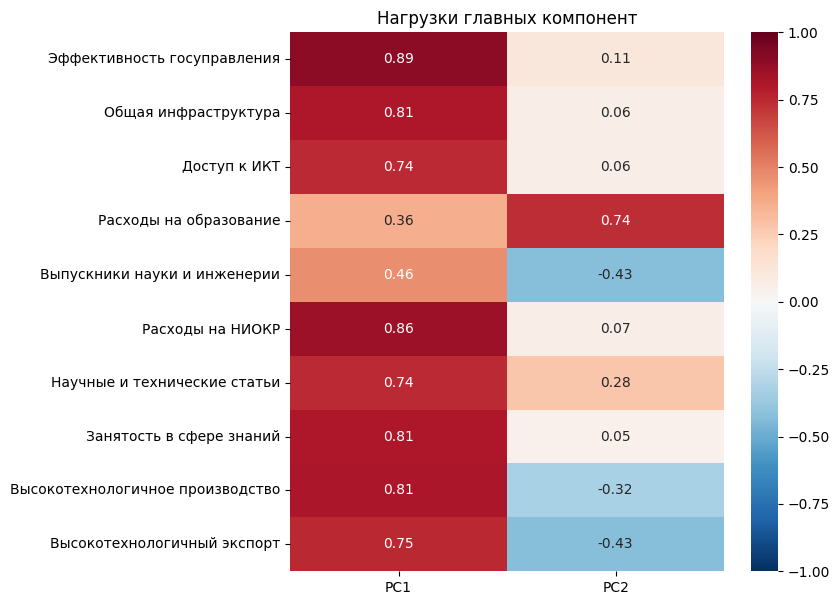

In [11]:
pca = PCA(n_components=2)
component_columns = ['PC1', 'PC2']

components = pd.DataFrame(
    pca.fit_transform(X_scaled),
    index=X.index,
    columns=component_columns
)

loadings = pd.DataFrame({
    'PC1': X_scaled.corrwith(components['PC1']),
    'PC2': X_scaled.corrwith(components['PC2'])
})

loadings.index = [feature_names[name] for name in features]

plt.figure(figsize=(7, 7))
sns.heatmap(loadings, annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Нагрузки главных компонент')
plt.show()

**Интерпретация компонент**<br>

PC1 - «Общее инновационно-технологическое развитие» (55,35% вариации). Все нагрузки положительные. Наибольшие нагрузки имеют эффективность госуправления = 0,89, расходы на НИОКР = 0,86, высокотехнологичное производство = 0,81, общая инфраструктура = 0,81 и занятость в сфере знаний = 0,81. Таким образом, высокие значения PC1 соответствуют сочетанию развитых институтов и инфраструктуры, исследовательской деятельности и технологичного сектора. 

PC2 - «Образовательные расходы и технологическая специализация» (11,21% вариации). Самая большая положительная нагрузка приходится на расходы на образование = 0,74, поменьше - на научные статьи = 0,28. Отрицательные нагрузки имеют высокотехнологичный экспорт = −0,43, доля выпускников науки и инженерии −0,43 и высокотехнологичное производство −0,32. 
У стран с высоким значением PC2 обычно выше показатель расходов на образование. Низкие значения PC2 чаще связаны с большей долей технических выпускников, высокотехнологичного производства и экспорта.

То есть PC1 описывает общий уровень инновационно-технологического развития, а PC2 показывает дополнительные различия в профиле стран.

**Сохранение компонент и итоговое признаковое пространство**<br>

Добавим PC1 и PC2 в df1 по исходным индексам строк.

In [13]:
df1[['PC1', 'PC2']] = components

cluster_features = ['PC1', 'PC2']
X_cluster = df1.loc[X.index, cluster_features].copy()

display(df1.loc[X.index, ['Country', 'PC1', 'PC2']].head(10))

print('Размер таблицы для кластеризации:', X_cluster.shape)
print('Количество пропусков:', X_cluster.isna().sum().sum())
display(X_cluster.corr().round(3))

,Country,PC1,PC2
0,Cote d'Ivoire,-2.542263,0.130051
1,Czechia,3.448805,-1.157530
2,"Egypt, Arab Rep.",-1.093940,-0.239842
3,"Hong Kong SAR, China",0.669485,0.978505
4,"Iran, Islamic Rep.",0.605435,-0.785389
5,"Korea, Rep.",4.845082,-1.093156
6,Lao PDR,-2.144421,-1.509100
7,Myanmar,-3.313878,-2.286630
9,Russian Federation,0.710656,-0.426737
10,Slovak Republic,1.820576,-1.128869


Размер таблицы для кластеризации: (132, 2)
Количество пропусков: 0


,PC1,PC2
PC1,1.0,-0.0
PC2,-0.0,1.0


**Итог по заданию 1.**<br>
Вместо 10 исходных показателей оставляем две главные компоненты PC1 и PC2. Для всех 132 стран рабочей выборки их значения рассчитаны без пропусков. Корреляция между компонентами близка к нулю, что соответствует свойству PCA. Вместе они объясняют 66,55% вариации исходных стандартизированных данных. Таким образом, мы сократили количество признаков с 10 до 2, потеряв 33,45% вариации.

Для кластеризации в задании 2 используем таблицу X_cluster, в которой находятся только PC1 и PC2. Исходные показатели сохраняем для описания кластеров, но при кластеризации используем только PC1 и PC2.

**2. Кластерный анализ и интерпретация результатов**

- Выберите подходящий алгоритм кластеризации. Кратко обоснуйте выбор (тип данных, размер выборки, интерпретируемость, устойчивость к выбросам). Укажите, почему другие рассмотренные в рамках курса методы не были выбраны.

- Определите оптимальное количество кластеров. Представьте график(и). Обоснуйте принятое решение.

- Рассчитайте описательные статистики по каждому кластеру. Подробно опишите каждый кластер, выделите его ключевые характеристики, отличающие от других кластеров.

- Дайте каждому кластеру осмысленное название. Обоснуйте выбор названий. Сформулируйте итоговые выводы о полученной сегментации.

In [8]:
# здесь можно написать код

**3. Апостериорный анализ и размышления над результатами**

- Сравните кластеры на основе значений категориальных переменных датасета. Например, рассмотрите как распределены страны разных регионов по кластерам или в какие кластеры в основном попали страны-члены ОЭСР? Сделайте содержательные выводы.

- Почему сформировалась именно такая кластерная структура? Соответствуют ли результаты вашим ожиданиям или оказались неожиданными?

In [9]:
# здесь можно написать ответ

### Комментарии к заданию и принципам его оценивания:
 
 - Все пункты задания должны сопровождаться _выполненным_ фрагментом кода.
 - Если результаты в виде статистических показателей, таблиц или графиков никак не прокомментированы и отсутствуют содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
 - Правильно выполненное задание оценивается в 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение других алгоритмов кластеризации и их применение для анализа данных, или развернутое и глубокое исследование имеющихся данных на основе применения всех пройденных на занятиях алгоритмов кластеризации, сравнением результатов и выбором лучшей кластерной модели с объяснением своего выбора.
 - В задании три пункта. Вес первого - 35%, второго - 50%, третьего - 15%. 
 - Задание можно выполнять индивидуально или в группе из 2 человек, критерии оценивания при этом остаются одинаковыми.
 - Если задание выполняется вдвоем, то в Smart LMS ноутбук с решениями загружает только один из студентов.
 - В названии загружаемого в Smart LMS файла нужно указать фамилию(ии) автора(ов) работы.
 - При использовании инструментов искусственного интеллекта необходимо отметить это в работе в соответствии с правилами НИУ ВШЭ.

### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и загрузить в Smart LMS до 21:00 9 ноября. Не рекомендую загружать файл в Smart LMS в последние несколько минут перед дедлайном. После дедлайна выполненные задания не принимаются.